# 04 · Reentrenamiento del CatBoost global

**Propósito:** entrenar el modelo final, un único CatBoost global para los 517 artículos, con todo el train (años 1–4, incluida la ventana de backtesting) y los hiperparámetros congelados del nb 03c, y guardarlo para el nb 05.

**Contexto (constitución 7.0.0):** el nb 03b trata los quiebres por tienda y exporta los datasets; el nb 03c busca los hiperparámetros con 13 folds (CatBoost, prueba 43: WRMSSE 0,506 frente a 0,894 del seasonal naive); el nb 03d muestra que elegir modelo por artículo es peor que CatBoost para todos (0,517 frente a 0,483 en los folds 8–13). Este notebook no busca ni elige nada: carga, comprueba y reentrena.

**Alcance:** no pronostica ni mide el test; eso es del nb 05, que reentrena en cada uno de sus 13 orígenes. El nb 04 anterior (tratamiento por artículo) quedó como `04_feature_engineering_y_seleccion_de_modelo_superseded.ipynb`, sin uso.

**Etapas** (el estado de cada una vive en `specs/001-abc-xyz-share-forecast/nb04-etapas.md`):

| # | Etapa |
|---|---|
| 0 | Decisiones y reglas |
| 1 | Carga de los datasets y de la configuración, y reproducción del backtest del 03c |
| 2 | Pronóstico a un paso y encadenado en la ventana, en tasas y en unidades |
| 3 | Reentrenamiento con todo el train |
| 4 | Guardado del modelo y cierre |

## Etapa 0 · Decisiones y reglas

**Objetivo:** fijar qué hace este notebook y con qué reglas, antes de escribir código.

**Decisiones propuestas:**

| # | Decisión | Justificación |
|---|---|---|
| D1 | **Entradas, cargadas y no recalculadas (R5):** `data/interim/nb03b_datasets/` (`boosting_data`, `rmsse_scale` y el manifiesto con las variables) y `data/interim/nb03c_boosting/catboost_backtest.pkl` (hiperparámetros de la prueba 43, lista de variables, semilla, versiones y el pronóstico de la ventana). | Constitución 7.0.0, Principio VI: lo que guardan el 03b y el 03c es la versión canónica y no se recalcula. |
| D2 | **Reproducir el 03c antes de reentrenar:** con lo cargado se repite el backtest de 13 folds (`boosting_backtest`, ~50 s) y debe dar los mismos pronósticos que el `.pkl` (diferencia máxima ≤ 1e-6 unidades) y su WRMSSE (0,5062). Si no coincide, el notebook se detiene. Se exige además la misma versión de CatBoost que el 03c (1.2.10). | Garantiza que el modelo que se entrena es el que se validó: mismos datos, mismas variables, mismos hiperparámetros y misma librería. Un cambio silencioso en cualquiera de ellos aparecería aquí y no en el test. |
| D3 | **Filas de ajuste:** todas las filas de train (`split == "train"`: antes de la ventana y sus 13 bloques, años 1–4) con objetivo; las filas con ratio tratado (vacío) no entrenan, igual que en el 03c. El test no entra. | Principio VI: el modelo final se entrena con todo lo anterior al test; la regla de ajuste es la del backtesting para no cambiar el modelo entre la validación y el reentrenamiento. |
| D4 | **Hiperparámetros sin cambios:** los de la prueba 43 tal cual (450 árboles, profundidad 4, sin early stopping), semilla del proyecto (42) y 6 hilos, como en el 03c. | Congelados (Principio VI). Con más filas no se reajusta `n_estimators`: hacerlo sería una nueva búsqueda. Mismos hilos para que la reproducción de D2 sea exacta. |
| D5 | **Salida:** `models/nb04_catboost/catboost_global.cbm` (formato nativo de CatBoost) y `meta.json` (hiperparámetros, variables y categóricas, semilla, filas y bloques de ajuste, versiones, fecha y origen: fecha del manifiesto del 03b y prueba del 03c). Con candado: si ya existe, el notebook se detiene salvo `RERUN = True`, y no se reemplaza salvo `OVERWRITE = True`. | `.cbm` lo lee cualquier versión de CatBoost sin depender de pickle ni de la versión de Python. El `meta.json` deja al nb 05 todo lo que necesita para reentrenar en cada origen con lo mismo. |
| D6 | **Lo que no hace:** ninguna búsqueda, ningún SARIMAX ni otro boosting, ningún pronóstico ni medición del test. Como diagnóstico, la importancia de las variables del modelo final. | Constitución 7.0.0, flujo de trabajo: el nb 04 solo reentrena; el test es del nb 05. |
| D7 | **Cómputo:** sin piloto (R7): el backtest de D2 tarda ~50 s y el ajuste final ~4 s (una de las 13 corridas, con algo más de filas). 6 hilos. | El tiempo ya está medido en el 03c (prueba 43: 44 s de ajuste en 13 folds). |

**Reglas que se mantienen:** R1–R8 de `CLAUDE.md`: una etapa a la vez, celdas md → import → run → check, todo número justificado, sin fuga (el test no entra).

## Configuración

**Qué hace:** fija la raíz del proyecto (rutas relativas), activa `%autoreload` para tomar los cambios de `src/` sin reiniciar el kernel, carga la configuración validada, fija la semilla e imprime las versiones (R6).

In [1]:
%load_ext autoreload
%autoreload 2

import os
import platform
import sys
from importlib.metadata import version
from pathlib import Path

# Raíz del código: el notebook corre desde notebooks/.
CODE_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(CODE_ROOT))
os.chdir(os.environ.get("PROJECT_ROOT", CODE_ROOT))

import numpy as np
import pandas as pd
from IPython.display import display

from src.config import load_validated_config

pd.set_option("display.max_columns", 30)

cfg = load_validated_config()
SEED = cfg["features"]["seed"]

LIBS = ["numpy", "pandas", "pyarrow", "catboost"]
display(pd.Series({"python": platform.python_version(), **{lib: version(lib) for lib in LIBS}}, name="versión").to_frame())
print(f"semilla: {SEED}")

,versión
python,3.12.3
numpy,2.5.4
pandas,3.1.0
pyarrow,26.0.0
catboost,1.2.10


semilla: 42


## Candado

**Qué hace:** detiene el notebook aquí si el modelo ya está guardado, para que un "Run All" accidental no lo vuelva a entrenar ni lo reemplace (D5).
**Para volver a ejecutar:** `RERUN = True`. Aun así, el modelo guardado solo se reemplaza con `OVERWRITE = True`.

In [2]:
from src.data import guard_rerun

MODEL_DIR = Path("models/nb04_catboost")   # D5: salida del notebook
RERUN = False       # True para volver a ejecutar aunque exista el modelo
OVERWRITE = False   # True solo para reemplazar el modelo guardado
guard_rerun([MODEL_DIR / "catboost_global.cbm", MODEL_DIR / "meta.json"], RERUN)

[]

## Etapa 1 · Carga y reproducción del backtest del 03c

**Objetivo:** tener en memoria los datasets del 03b y la configuración congelada de CatBoost del 03c, y comprobar que juntos reproducen exactamente el backtest con el que se validó (D1, D2).
**Entradas:**
- `data/interim/nb03b_datasets/` (nb 03b, 13.3): `boosting_data` (variables, `split`, `fold`, `ratio`, `units`, `units_prev`), `rmsse_scale` y el manifiesto (variables y categóricas).
- `data/interim/nb03c_boosting/catboost_backtest.pkl` (nb 03c, 5.3): hiperparámetros de la prueba 43, variables, semilla, versiones y el pronóstico de la ventana.
- Gasto diario por artículo (`load_interim`, solo hasta el último día de train) y el calendario, para los pesos del WRMSSE (gasto en los últimos 13 bloques de train, Principio VII).

**Salidas:** `boosting_data`, `FEATURES`, `PARAMS`, `rmsse_scale`, `weights` y `repro` (backtest de 13 folds repetido aquí).
**Decisión:**
- Las variables y los hiperparámetros salen del `.pkl` del 03c tal cual; se exige que coincidan con el manifiesto del 03b y que la versión de CatBoost sea la misma.
- `repro` debe dar los mismos pronósticos que el 03c, fila a fila (diferencia ≤ 1e-6 unidades), y el mismo WRMSSE (0,5062), con la misma semilla y los mismos 6 hilos (usuario, 2026-11-09). Si no, el notebook se detiene aquí.

In [3]:
from src.config import train_end
from src.data import load_calendar, load_interim, load_tables
from src.features import BLOCK_DAYS
from src.metrics import spend_weights, train_weight_windows, wrmsse_frame
from src.modeling import boosting_backtest

DATASETS_DIR = Path("data/interim/nb03b_datasets")                         # nb 03b, 13.3
CATBOOST_FILE = Path("data/interim/nb03c_boosting/catboost_backtest.pkl")  # nb 03c, 5.3 (prueba 43)
N_THREADS = 6        # D4: los mismos hilos del 03c, para que la reproducción sea exacta
WEIGHT_BLOCKS = 13   # pesos del WRMSSE: gasto en los últimos 13 bloques de train (Principio VII)
REPRO_TOL = 1e-6     # D2: diferencia máxima admitida en unidades frente al 03c

In [4]:
inputs, manifest = load_tables(DATASETS_DIR)
catboost = pd.read_pickle(CATBOOST_FILE)
boosting_data = inputs["boosting_data"]
rmsse_scale = inputs["rmsse_scale"].set_index("item_id")["scale"]
FEATURES = catboost["meta"]["features"]
PARAMS = catboost["meta"]["params"]

cal = load_calendar(cfg)
day_of = pd.Series(cal["d"].str[2:].astype(int).to_numpy(), index=pd.to_datetime(cal["date"]))   # fecha → día d
interim = load_interim(cfg, max_day=train_end(cfg))   # gasto diario solo hasta el último día de train
weights = spend_weights(interim["item_spend"], interim["item_ids"],
                        train_weight_windows(boosting_data, day_of, WEIGHT_BLOCKS, BLOCK_DAYS))

In [5]:
repro = boosting_backtest(boosting_data, FEATURES, "catboost", PARAMS, SEED, N_THREADS)

In [6]:
meta = catboost["meta"]
print(f"nb 03b exportado: {manifest['saved_at']} · CatBoost: prueba {meta['trial']} de {meta['n_trials']}, guardado {meta['saved_at']}")
# Misma configuración y misma librería que el 03c.
assert meta["algorithm"] == "catboost" and meta["seed"] == SEED == manifest["seed"]
assert version("catboost") == meta["versions"]["catboost"], (version("catboost"), meta["versions"]["catboost"])
assert FEATURES == manifest["boost_features"] and set(PARAMS["cat_features"]) == set(manifest["cat_features"])
n_items = manifest["n_items"]
assert boosting_data["item_id"].nunique() == n_items == len(rmsse_scale) == len(weights) and (weights > 0).all()
assert set(boosting_data["split"].unique()) == {"train", "test"}
# Reproducción exacta (D2): mismas filas y mismos pronósticos que el 03c.
saved = catboost["backtest"].assign(item_id=lambda d: d["item_id"].astype(str))
both = saved.merge(repro, on=["item_id", "block", "fold"], suffixes=("_03c", ""), validate="one_to_one")
assert len(both) == len(saved) == len(repro) == n_items * manifest["n_folds"]
max_diff = float((both["pred"] - both["pred_03c"]).abs().max())
repro_wrmsse = wrmsse_frame(repro, "pred", rmsse_scale, weights)[0]
assert max_diff <= REPRO_TOL, max_diff
assert np.isclose(repro_wrmsse, meta["wrmsse"], rtol=0, atol=1e-9), (repro_wrmsse, meta["wrmsse"])
print(f"reproducción: diferencia máxima {max_diff:.2e} unidades · WRMSSE {repro_wrmsse:.4f} (03c: {meta['wrmsse']:.4f})")

display(pd.Series(PARAMS, name="valor").rename_axis("hiperparámetro").to_frame())
display(boosting_data.groupby("split", observed=True).agg(filas=("item_id", "size"), con_objetivo=("ratio", "count")))
display(repro.sample(5, random_state=SEED))

nb 03b exportado: 2026-11-07T08:25:38 · CatBoost: prueba 43 de 100, guardado 2026-11-07T14:35:13
reproducción: diferencia máxima 0.00e+00 unidades · WRMSSE 0.5062 (03c: 0.5062)


,valor
hiperparámetro,
loss_function,RMSE
border_count,64
bootstrap_type,Bernoulli
boosting_type,Plain
cat_features,"[item_id, cell, period]"
depth,4
n_estimators,450
learning_rate,0.071058
l2_leaf_reg,2.909726


,filas,con_objetivo
split,,
test,6721,6711
train,24443,24348


,item_id,block,fold,units,units_prev,ratio_hat,pred
3552,HOUSEHOLD_1_369,46,7,322.357143,371.000000,0.893486,331.483153
4108,HOUSEHOLD_1_506,47,8,615.750000,756.785714,0.971226,735.010000
549,FOODS_1_184,41,2,1214.535714,1502.000000,0.971396,1459.036282
1163,FOODS_3_139,42,3,396.750000,518.500000,0.988389,512.479906
1881,HOBBIES_1_228,43,4,346.000000,343.000000,0.948455,325.319911


## Etapa 2 · Pronóstico a un paso y encadenado en la ventana, en tasas y en unidades

**Objetivo:** ver en un mismo lugar, sobre los 13 bloques de la ventana de backtesting, las dos formas de pronosticar y su error, en tasas y en unidades (usuario, 2026-11-09):
- **A un paso** (los folds de la Etapa 1): cada bloque se pronostica con lo observado hasta el bloque anterior; sus unidades parten de las **reales** del bloque anterior.
- **Encadenado** (como en producción): desde el inicio de la ventana se pronostican los 13 bloques de una vez; cada bloque parte de lo **pronosticado** para el anterior.

**Entradas:** `boosting_data`, `FEATURES`, `PARAMS`, `repro`, `rmsse_scale`, `weights` y `manifest` (Etapa 1); `target_lags`, `rolling_windows` y `rolling_stats` de `params.toml`.
**Salidas:** `chain` (una fila por artículo y bloque de la ventana con la tasa y las unidades reales, a un paso y encadenadas), `summary` (WRMSSE y WAPE por nivel, forma y segmento), `by_step` (lo mismo por paso) y los gráficos de los 517 artículos.

**Decisión:**
- **Origen del encadenado:** el último bloque antes de la ventana de cada artículo; todo dentro de train, el test no se toca. **Modelo:** el del fold 1 (entrenado solo con lo anterior al origen, filas con ratio tratado fuera), el mismo que pronosticó el fold 1 en la Etapa 1.
- **Tasas encadenadas:** en el paso h, los rezagos y ventanas del ratio (`ratio_lag*`, `ratio_roll*`) se recalculan con la historia real hasta el origen más las tasas pronosticadas en los pasos 1 a h − 1 (mismas funciones del dataset). El calendario, la edad, `item_id` y `cell` se conocen de antemano. `ratio_lag13` nunca se encadena: hasta 13 pasos cae en un bloque real.
- **Unidades:** a un paso, Û(t) = U(t−1) real × r̂(t). Encadenado, Û(t+1) = U(t) real del origen × r̂(t+1) y en adelante Û(t+h) = Û(t+h−1) × r̂(t+h).
- **Errores, iguales en los dos niveles:** WRMSSE (criterio), WAPE (secundaria) y MAE (diagnóstico), con los pesos de la Etapa 1. En unidades, la escala del RMSSE es la del 03b; en tasas, la misma definición aplicada a la tasa: media de (r_t − r_{t−13})² en todo el train del artículo. Se reportan por segmento y por paso.
- **Gráfico por artículo:** arriba tasas, abajo unidades; real, a un paso (naranja) y encadenado (azul), con el WAPE y el RMSSE de cada uno; a la derecha el error de cada bloque. Se muestran 5 artículos al azar por segmento (semilla) y se guardan los 517 en `reports/figures/nb04_catboost_backtest/<segmento>/<item_id>.png` (110 ppp; se sobrescriben, no alimentan decisiones).
- **Chequeos:** en el paso 1 no hay nada encadenado, así que tasa y unidades deben ser exactamente las del fold 1; las unidades encadenadas deben ser el paso anterior × su tasa; el WRMSSE a un paso debe ser el de la Etapa 1 (0,5062).

In [7]:
import matplotlib.pyplot as plt

from src.metrics import item_errors, seasonal_naive_scale, segment_errors
from src.modeling import chain_units, fold_masks, make_booster, plot_forecast_item, recursive_ratio_forecast

FE = cfg["features"]
HORIZON = 13               # bloques hacia adelante (usuario): un año de bloques de 28 días
SEGMENTS = ["AX", "AY", "AZ"]
SAMPLE_PER_SEGMENT = 5     # usuario
FIG_DIR = Path("reports/figures/nb04_catboost_backtest")   # reports/ es parte de la estructura fija (Principio III)
FIG_DPI = 110              # se lee bien en pantalla y pesa poco
KINDS = {"1step": "a un paso", "chain": "encadenado"}

In [8]:
# Encadenado: modelo del fold 1 y 13 tasas desde el inicio de la ventana.
train1, _ = fold_masks(boosting_data, 1)
fit1 = train1 & boosting_data["ratio"].notna()
model_f1 = make_booster("catboost", PARAMS, SEED, N_THREADS)
model_f1.fit(boosting_data.loc[fit1, FEATURES], boosting_data.loc[fit1, "ratio"])
chain = recursive_ratio_forecast(boosting_data, model_f1, FEATURES, FE["target_lags"], FE["rolling_windows"],
                                 FE["rolling_stats"], first_fold=1, horizon=HORIZON).rename(columns={"ratio_hat": "ratio_chain"})

# Real y a un paso (Etapa 1) en la misma tabla.
real = boosting_data[["item_id", "block", "units", "ratio_raw", "cell"]].assign(item_id=lambda d: d["item_id"].astype(str))
chain = (chain.merge(real, on=["item_id", "block"], validate="one_to_one")
              .merge(repro[["item_id", "block", "ratio_hat", "pred"]].rename(columns={"ratio_hat": "ratio_1step", "pred": "units_1step"}),
                     on=["item_id", "block"], validate="one_to_one"))
chain["cell"] = chain["cell"].astype(str)
first = boosting_data[boosting_data["fold"] == 1]
origin_units = pd.Series(first["units_prev"].to_numpy(float), index=first["item_id"].astype(str))   # unidades reales del origen
chain["units_chain"] = chain_units(chain, origin_units, ratio_col="ratio_chain")

# Escala del RMSSE en tasas: misma definición que en unidades, con la tasa real de todo el train.
train_rows = boosting_data[boosting_data["split"] == "train"].sort_values(["item_id", "block"])
rate_scale = train_rows.groupby(train_rows["item_id"].astype(str))["ratio_raw"].apply(
    lambda r: seasonal_naive_scale(r.to_numpy(float), manifest["snaive_m"]))

# Errores en los dos niveles.
cell_of = chain.groupby("item_id")["cell"].first()
LEVELS = {"tasas": ("ratio", "ratio_raw", rate_scale), "unidades": ("units", "units", rmsse_scale)}
def level_errors(df):
    return {lvl: item_errors(df, [f"{p}_{k}" for k in KINDS], scale, actual_col=act).assign(
                candidate=lambda d: d["candidate"].str.split("_").str[-1].map(KINDS))
            for lvl, (p, act, scale) in LEVELS.items()}
errors = level_errors(chain)
summary = pd.concat({lvl: segment_errors(e, weights, cell_of) for lvl, e in errors.items()}, names=["nivel"])
by_step = pd.concat({(lvl, h): segment_errors(e, weights, cell_of).xs("total", level="segment")
                     for h, g in chain.groupby("step") for lvl, e in level_errors(g).items()}, names=["nivel", "step"])

In [9]:
assert len(chain) == n_items * HORIZON
assert chain[["ratio_raw", "ratio_1step", "ratio_chain", "units", "units_1step", "units_chain"]].notna().all().all()
assert not boosting_data.loc[fit1, "fold"].ge(1).any()                       # el modelo del encadenado no vio la ventana
assert rate_scale.notna().all() and (rate_scale > 0).all() and len(rate_scale) == n_items
# Paso 1 = fold 1 (nada encadenado todavía), en tasa y en unidades.
s1 = chain[chain["step"] == 1]
assert np.allclose(s1["ratio_chain"], s1["ratio_1step"], rtol=0, atol=1e-9)
assert np.allclose(s1["units_chain"], s1["units_1step"], rtol=1e-12)
# Unidades encadenadas = paso anterior × su tasa; a un paso = real anterior × su tasa.
c = chain.sort_values(["item_id", "step"])
prev = c.groupby("item_id")["units_chain"].shift(1).fillna(c["item_id"].map(origin_units))
assert np.allclose(c["units_chain"], prev * c["ratio_chain"])
# A un paso reproduce el WRMSSE de la Etapa 1.
assert np.isclose(summary.xs(("unidades", "a un paso", "total"))["wrmsse"], repro_wrmsse)

print("WRMSSE y WAPE en los 13 bloques de la ventana, por segmento:")
display(summary[["wrmsse", "wape"]].unstack(["nivel", "candidate"]).reindex(SEGMENTS + ["total"])
        .reorder_levels([1, 0, 2], axis=1).sort_index(axis=1, level=[0, 1], sort_remaining=False).round(4))
print("WRMSSE y WAPE por paso (todos los artículos):")
display(by_step[["wrmsse", "wape"]].unstack("step").round(4))
print("MAE por artículo (diagnóstico; tasas en tasa, unidades en unidades):")
display(pd.concat({lvl: e.groupby("candidate")["mae"].agg(media="mean", mediana="median") for lvl, e in errors.items()},
                  names=["nivel"]).round(3))
display(chain.sample(5, random_state=SEED))

WRMSSE y WAPE en los 13 bloques de la ventana, por segmento:


nivel         tasas                                  unidades             \
               wape               wrmsse                 wape              
candidate a un paso encadenado a un paso encadenado a un paso encadenado   
segment                                                                    
AX           0.0792     0.0846    0.7348     0.7801    0.0738     0.1040   
AY           0.1099     0.1146    0.6315     0.6519    0.1070     0.1805   
AZ           0.1379     0.1340    0.6381     0.6313    0.1358     0.3837   
total        0.1038     0.1072    0.6711     0.6959    0.1023     0.2020   

nivel                           
             wrmsse             
candidate a un paso encadenado  
segment                         
AX           0.5553     0.7412  
AY           0.4747     0.6823  
AZ           0.4832     0.8929  
total        0.5062     0.7418

WRMSSE y WAPE por paso (todos los artículos):


wrmsse                                                  \
step                     1       2       3       4       5       6       7    
nivel    candidate                                                            
tasas    a un paso   0.5038  0.5411  0.5907  0.4842  0.5236  0.5166  0.4677   
         encadenado  0.5038  0.5516  0.5909  0.5406  0.5449  0.5201  0.4780   
unidades a un paso   0.3748  0.4138  0.4617  0.3645  0.4087  0.3921  0.3507   
         encadenado  0.3748  0.4699  0.6464  0.6091  0.6003  0.6381  0.6366   

                                                                       wape  \
step                     8       9       10      11      12      13      1    
nivel    candidate                                                            
tasas    a un paso   0.5234  0.6352  0.5535  0.5086  0.4670  0.4745  0.1057   
         encadenado  0.5245  0.6774  0.6312  0.5247  0.4801  0.4806  0.1057   
unidades a un paso   0.3845  0.4760  0.4026  0.3816  0.3451  0.3499  0.0956   
         encadenado  0.6995  0.7132  0.7040  0.6742  0.6381  0.6865  0.0956   

                                                                             \
step                     2       3       4       5       6       7       8    
nivel    candidate                                                            
tasas    a un paso   0.0968  0.1101  0.0962  0.1088  0.1074  0.1005  0.1113   
         encadenado  0.0997  0.1127  0.1035  0.1106  0.1083  0.1023  0.1108   
unidades a un paso   0.1034  0.1229  0.0902  0.1083  0.1086  0.0955  0.1043   
         encadenado  0.1228  0.1831  0.1772  0.2001  0.2323  0.2384  0.2723   

                                                             
step                     9       10      11      12      13  
nivel    candidate                                           
tasas    a un paso   0.1130  0.1090  0.1030  0.0948  0.0925  
         encadenado  0.1233  0.1149  0.1089  0.0985  0.0935  
unidades a un paso   0.1269  0.0977  0.0985  0.0843  0.0945  
         encadenado  0.2477  0.2409  0.2281  0.2025  0.2182

MAE por artículo (diagnóstico; tasas en tasa, unidades en unidades):


media  mediana
nivel    candidate                   
tasas    a un paso     0.105    0.096
         encadenado    0.108    0.099
unidades a un paso   105.414   52.544
         encadenado  208.140   80.435

,item_id,block,fold,step,ratio_chain,units,ratio_raw,cell,ratio_1step,units_1step,units_chain
3552,HOUSEHOLD_1_369,46,7,7,0.948009,322.357143,0.868887,AX,0.893486,331.483153,328.500905
4108,HOUSEHOLD_1_506,47,8,8,0.942051,615.750000,0.813639,AY,0.971226,735.010000,869.105396
549,FOODS_1_184,41,2,2,0.960877,1214.535714,0.808612,AY,0.971396,1459.036282,1518.303909
1163,FOODS_3_139,42,3,3,1.014493,396.750000,0.765188,AX,0.988389,512.479906,508.142222
1881,HOBBIES_1_228,43,4,4,0.954582,346.000000,1.008746,AX,0.948455,325.319911,321.553611


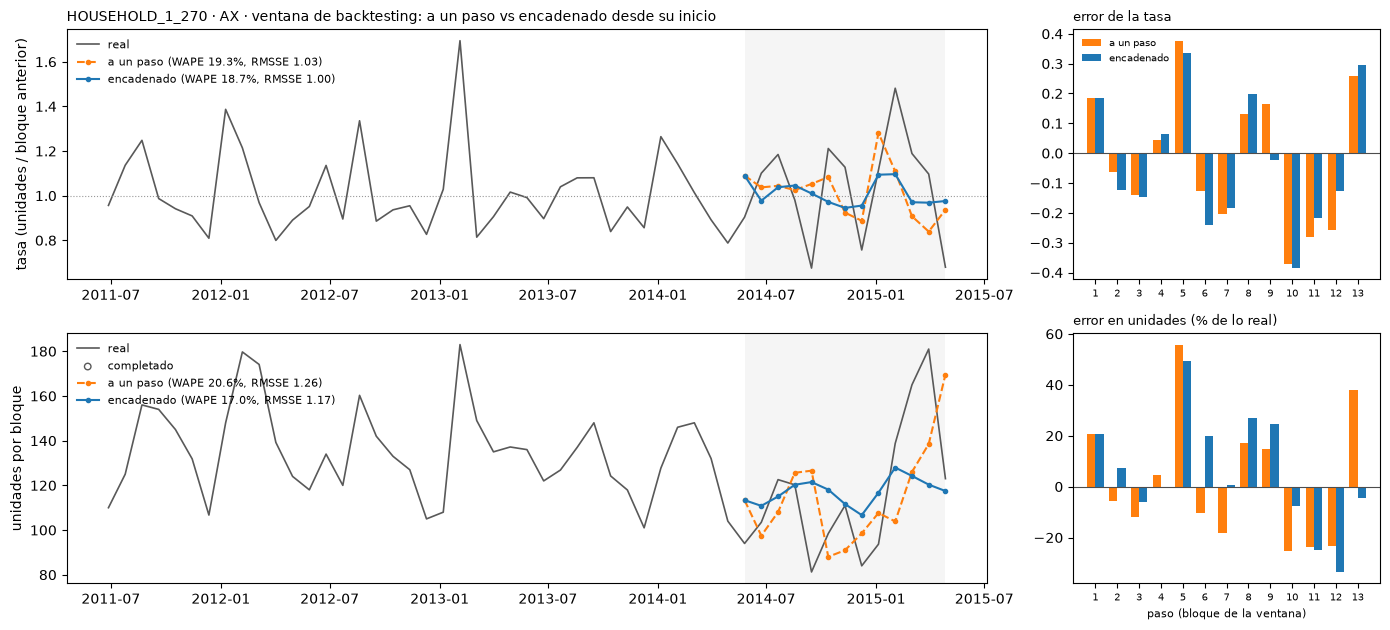

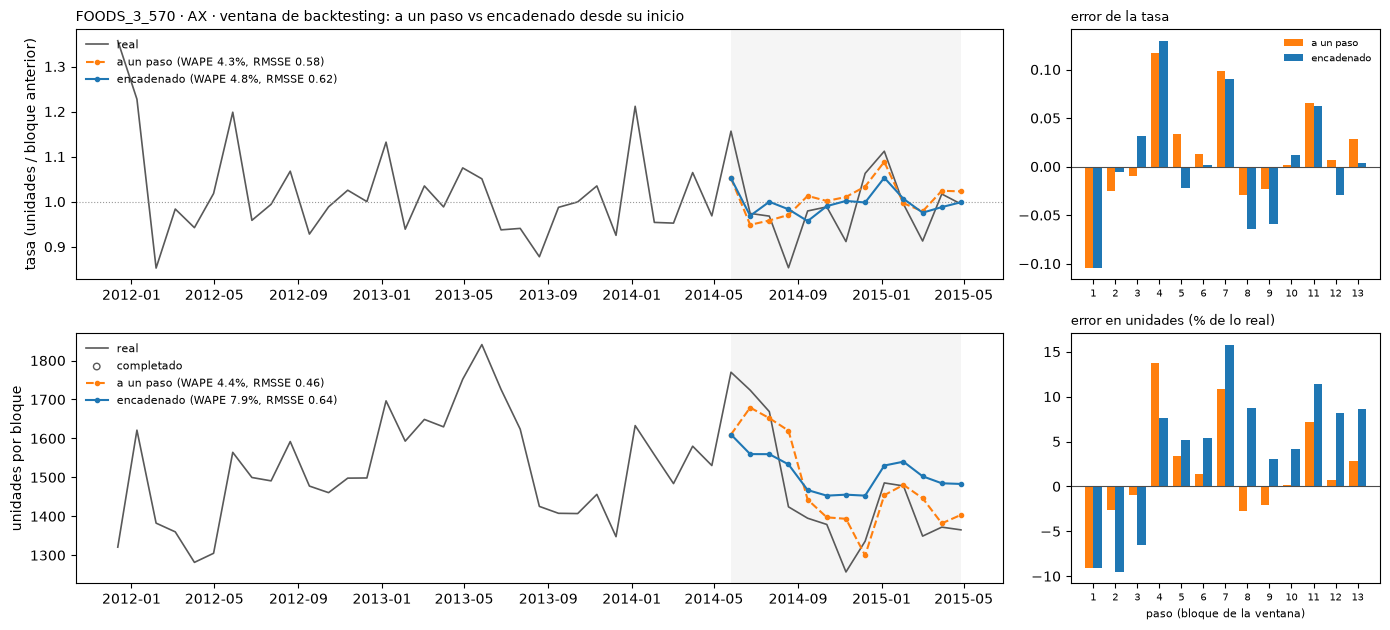

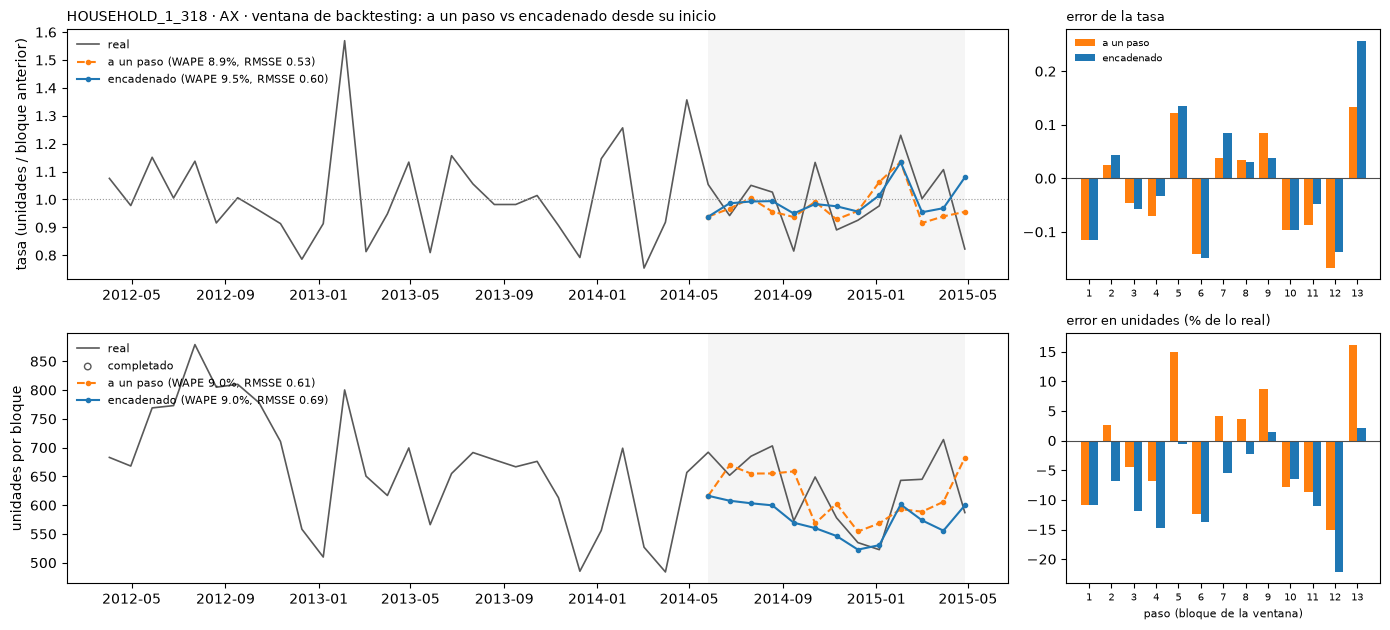

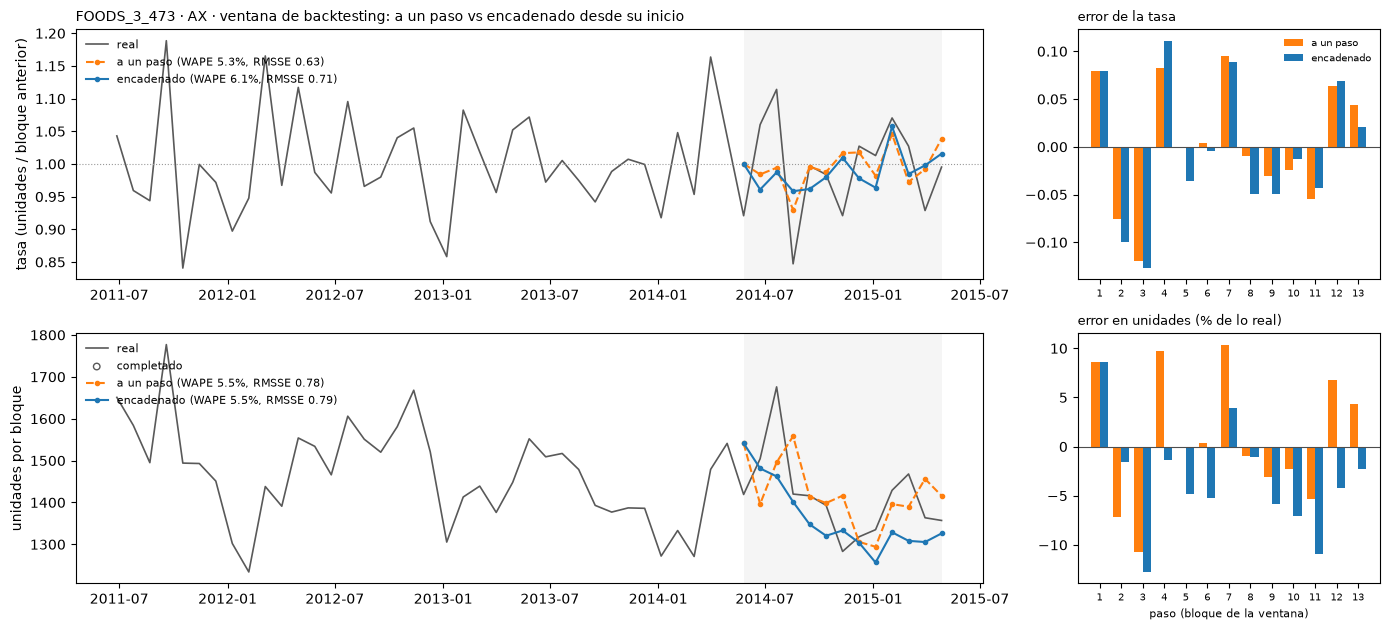

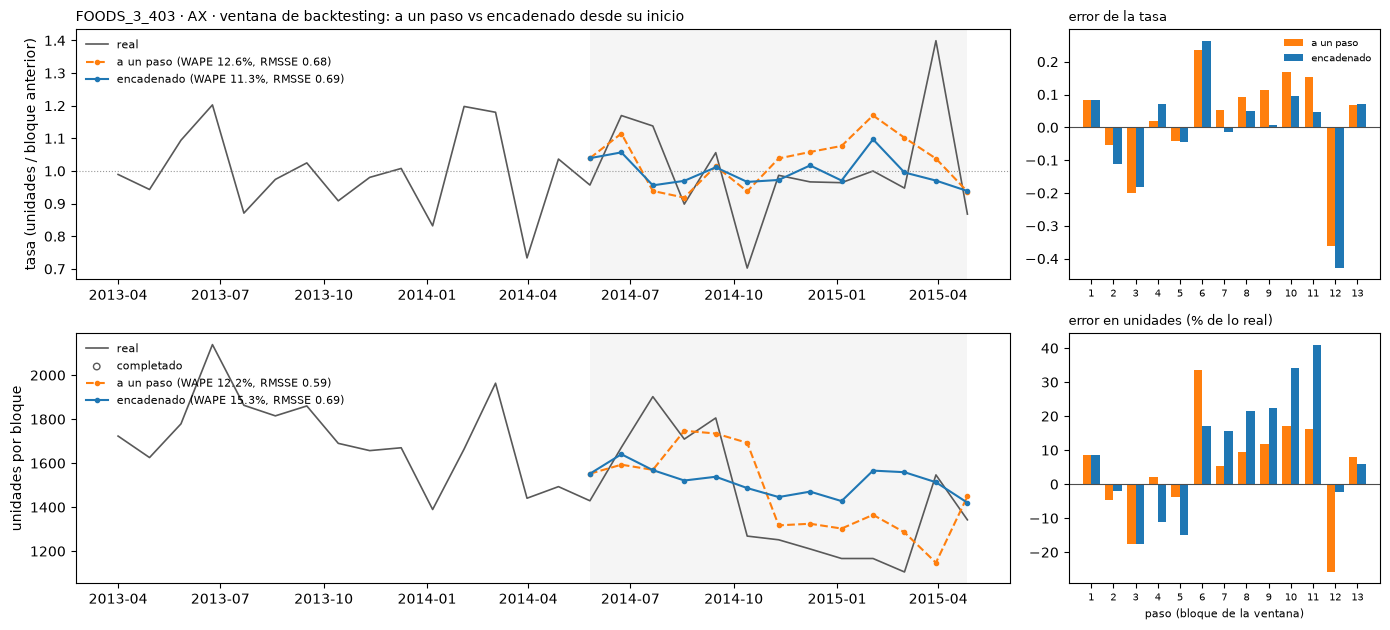

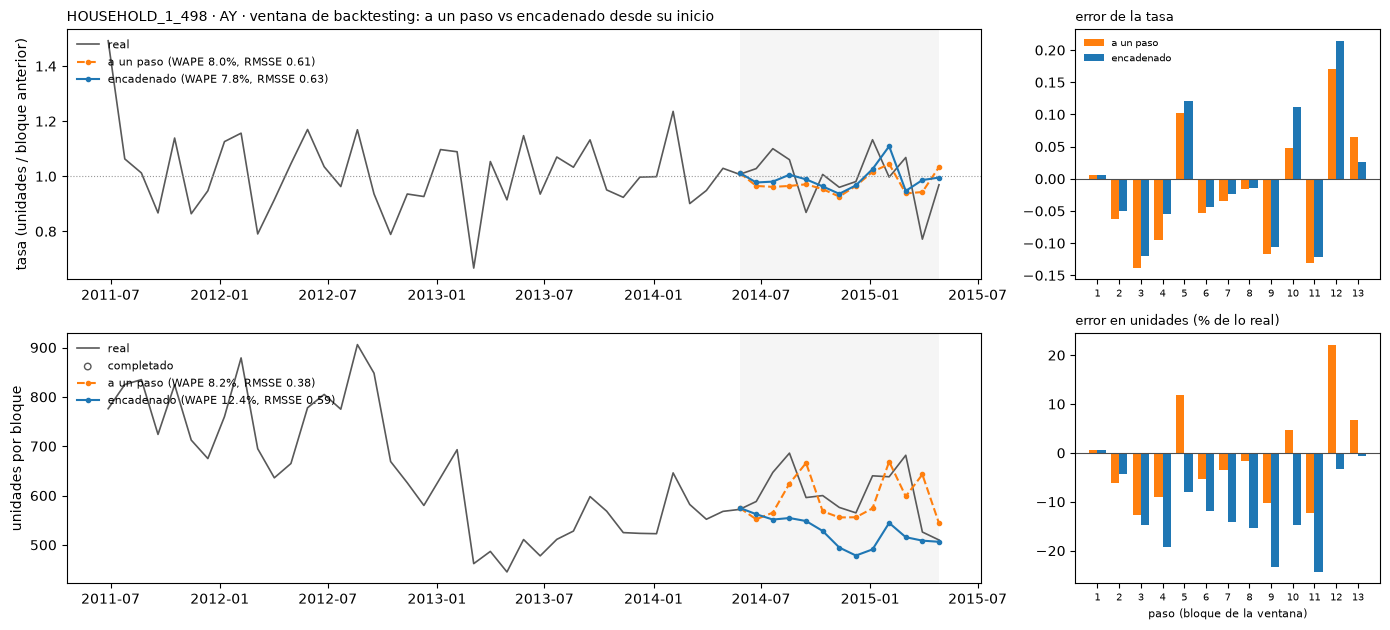

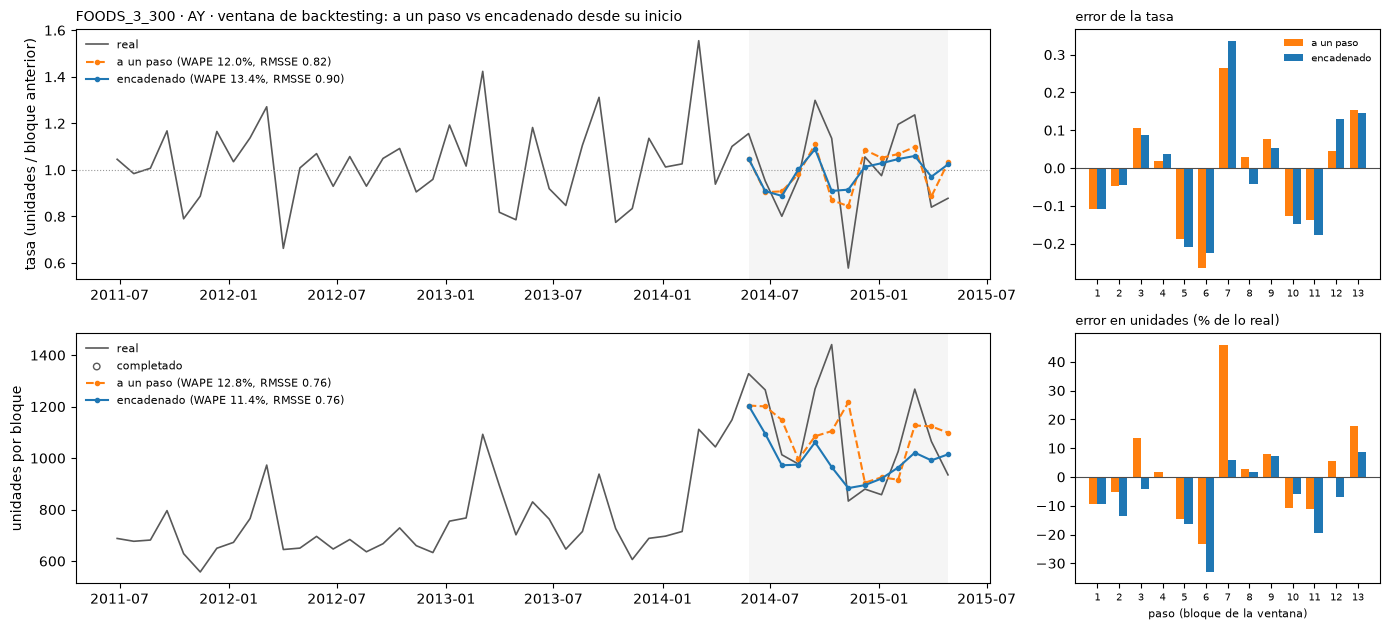

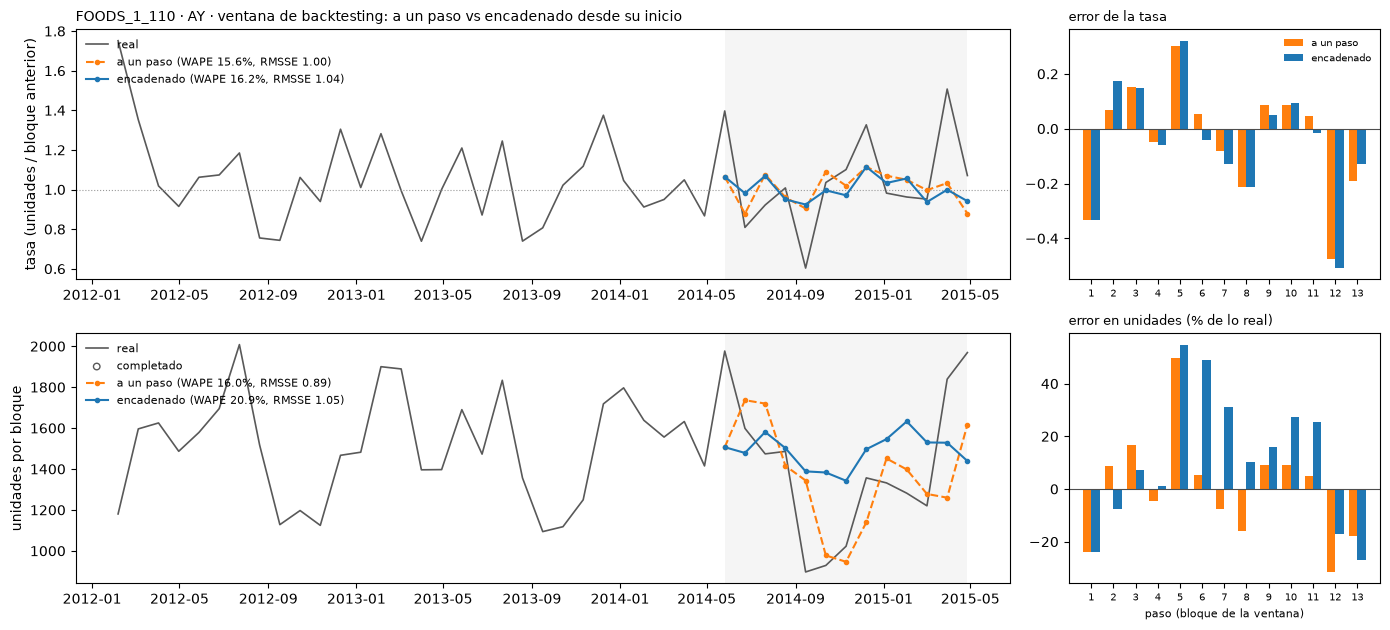

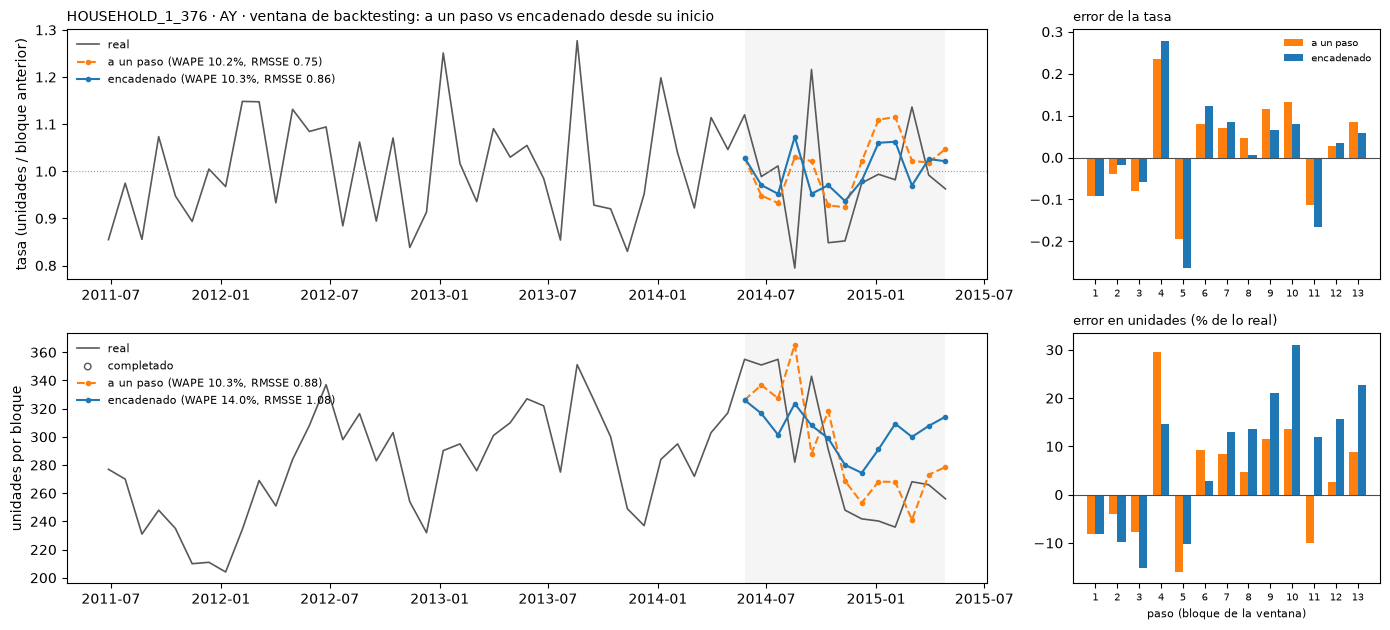

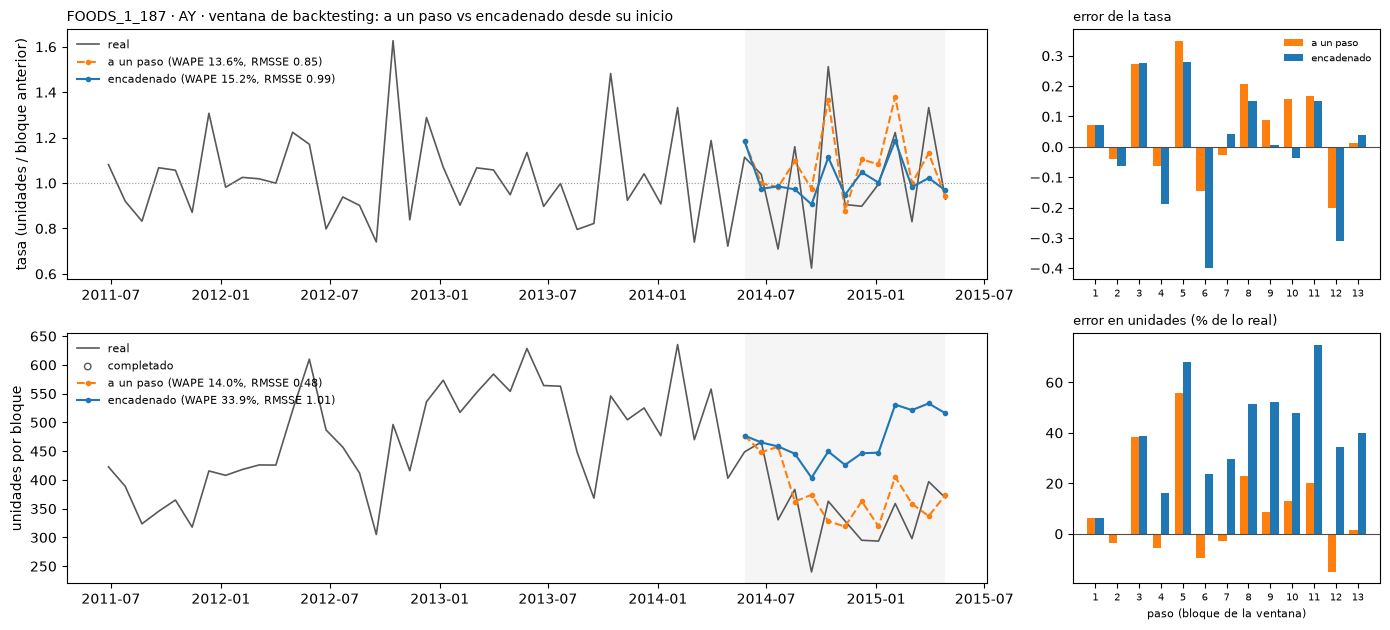

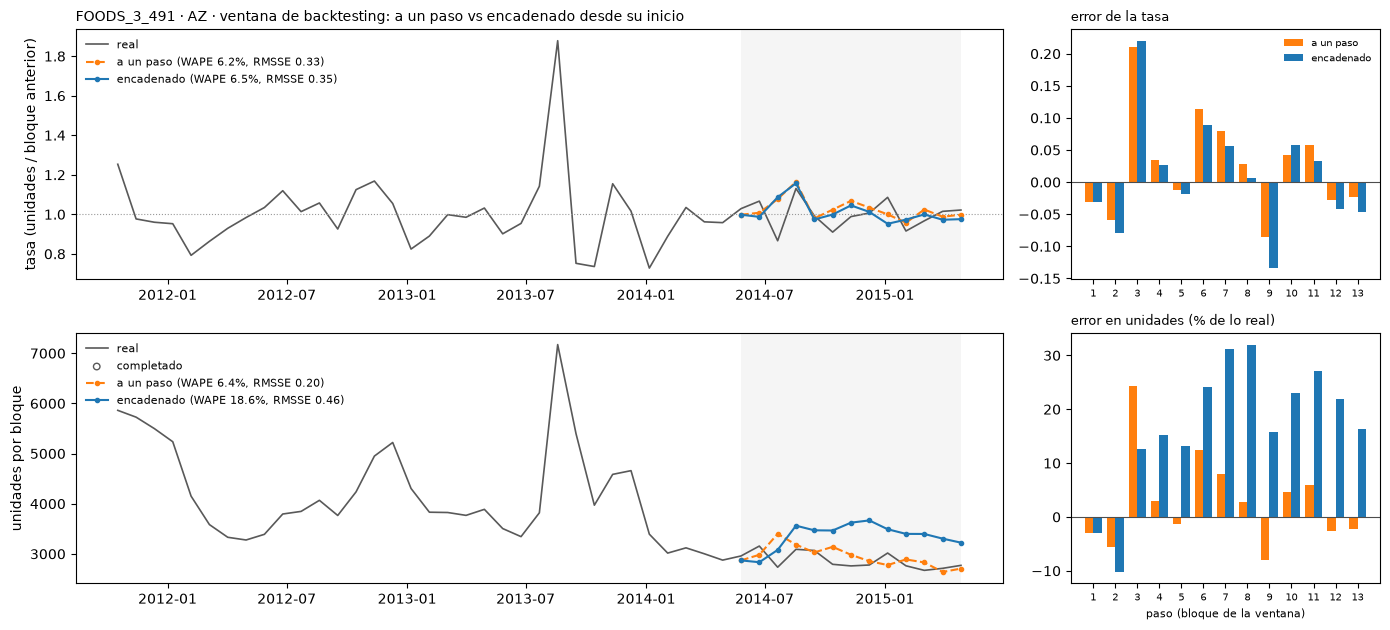

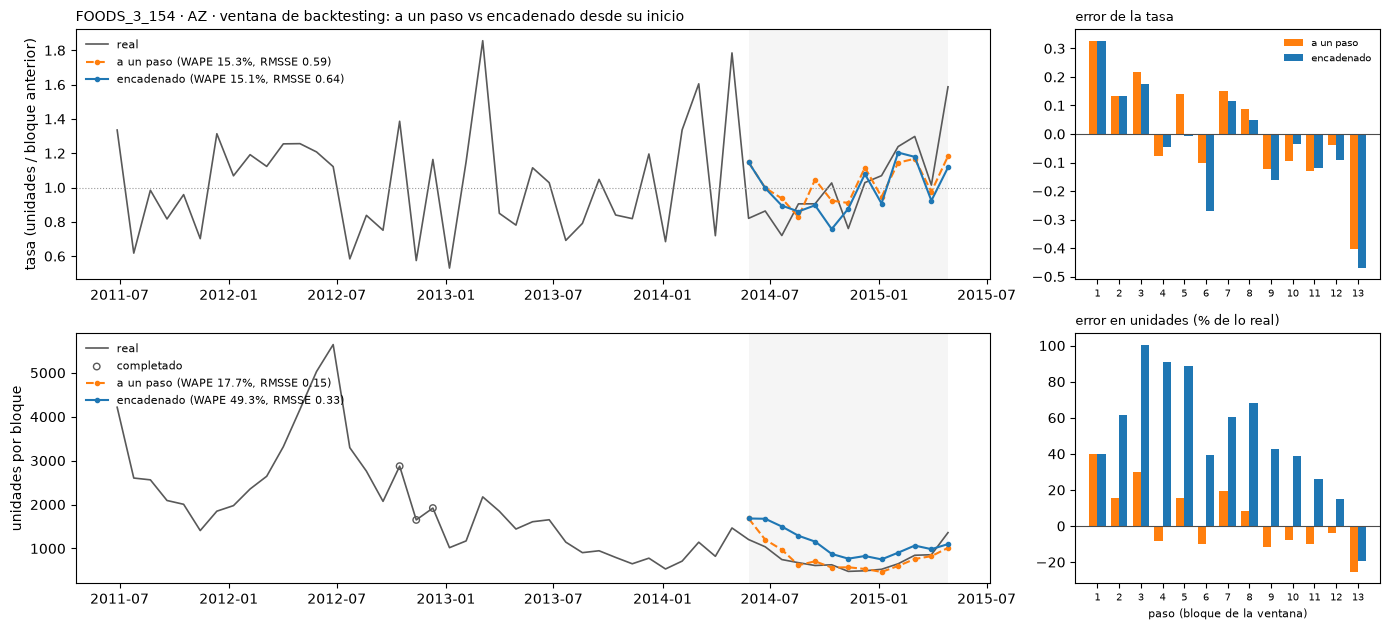

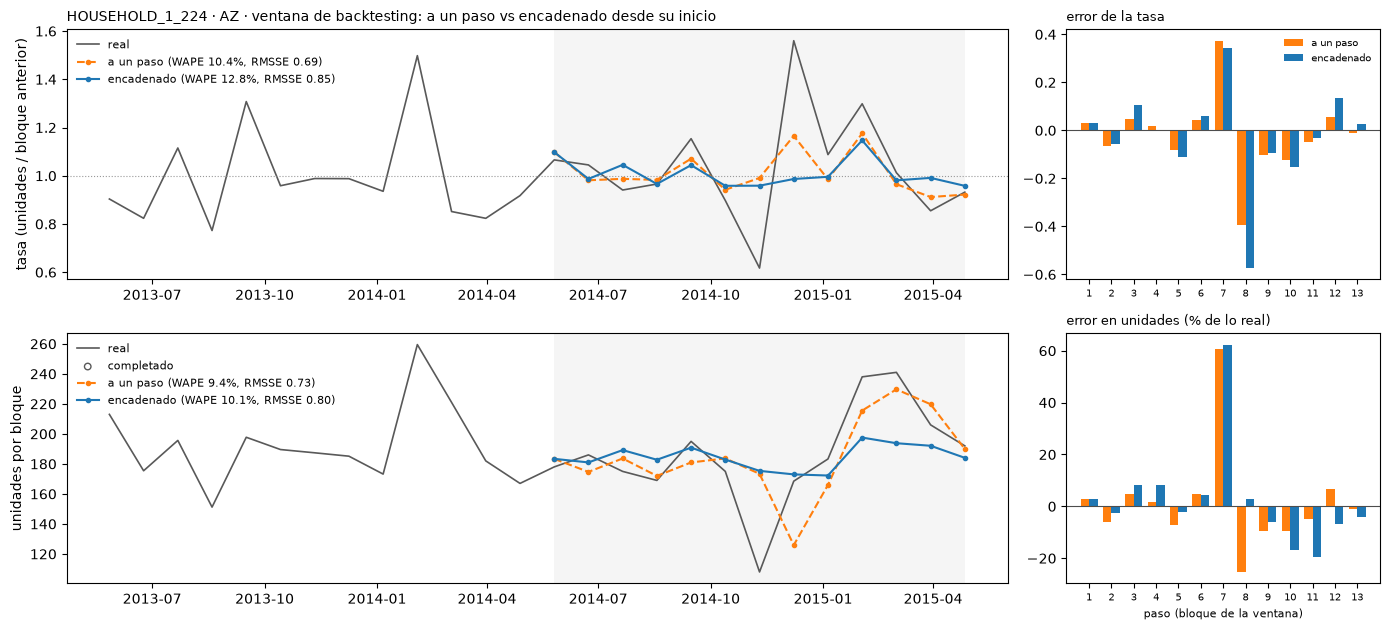

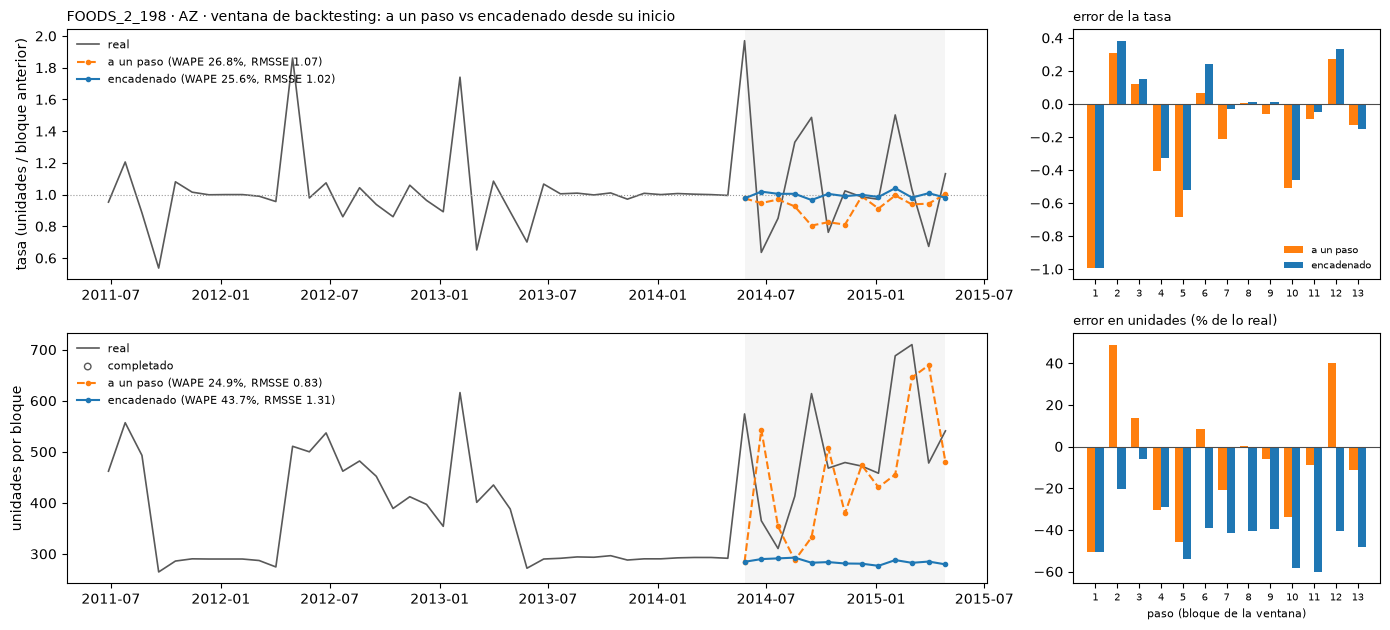

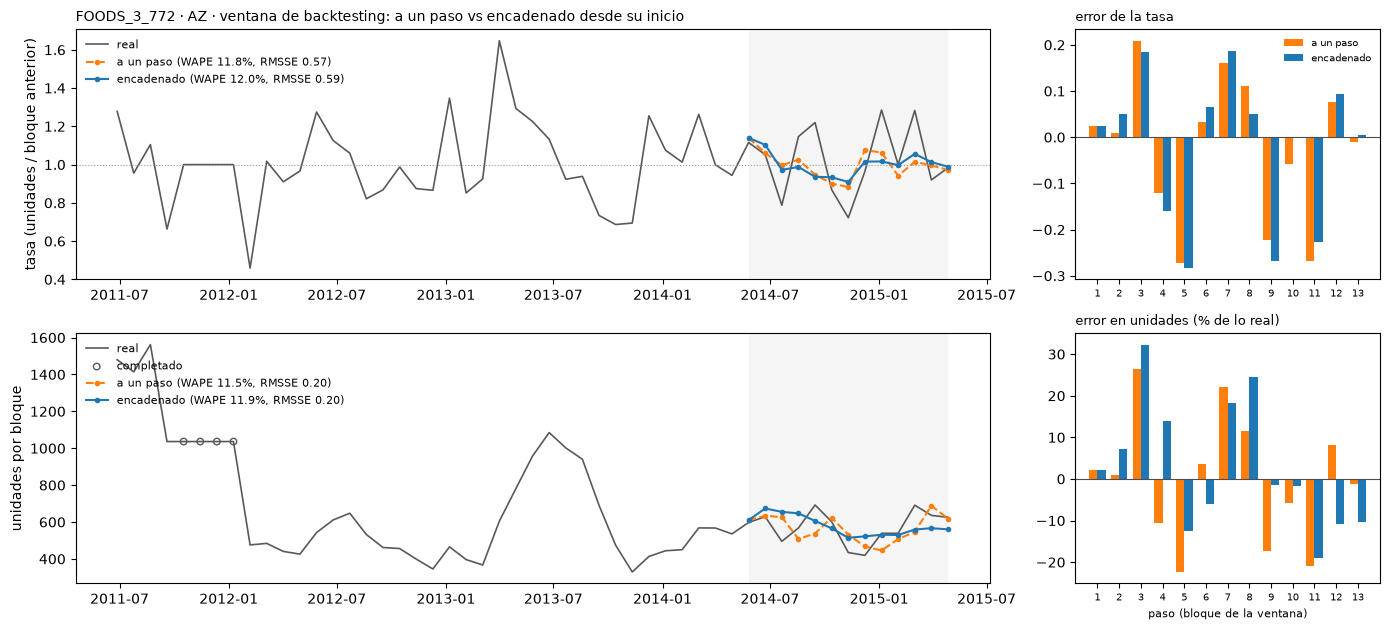

In [10]:
sample = {seg: cell_of[cell_of == seg].sample(SAMPLE_PER_SEGMENT, random_state=SEED).index.tolist() for seg in SEGMENTS}
for seg, ids in sample.items():
    for item in ids:
        fig = plot_forecast_item(boosting_data, chain, item, float(rate_scale[item]), float(rmsse_scale[item]))
        fig.tight_layout()
        plt.show()

In [11]:
for item, seg in cell_of.items():
    out_dir = FIG_DIR / seg
    out_dir.mkdir(parents=True, exist_ok=True)
    fig = plot_forecast_item(boosting_data, chain, item, float(rate_scale[item]), float(rmsse_scale[item]))
    fig.tight_layout()
    fig.savefig(out_dir / f"{item}.png", dpi=FIG_DPI)
    plt.close(fig)

In [12]:
saved = {seg: sorted(p.stem for p in (FIG_DIR / seg).glob("*.png")) for seg in SEGMENTS}
for seg in SEGMENTS:
    assert saved[seg] == sorted(cell_of[cell_of == seg].index), seg   # cada artículo en la carpeta de su segmento
size_mb = sum(p.stat().st_size for p in FIG_DIR.rglob("*.png")) / 1e6
display(pd.Series({seg: len(v) for seg, v in saved.items()}, name="gráficos").rename_axis("segmento").to_frame())
print(f"{FIG_DIR}: {sum(map(len, saved.values()))} gráficos, {size_mb:.1f} MB")
display(pd.DataFrame(sample).rename_axis("muestra"))

,gráficos
segmento,
AX,191
AY,229
AZ,97


reports/figures/nb04_catboost_backtest: 517 gráficos, 82.3 MB


,AX,AY,AZ
muestra,,,
0,HOUSEHOLD_1_270,HOUSEHOLD_1_498,FOODS_3_491
1,FOODS_3_570,FOODS_3_300,FOODS_3_154
2,HOUSEHOLD_1_318,FOODS_1_110,HOUSEHOLD_1_224
3,FOODS_3_473,HOUSEHOLD_1_376,FOODS_2_198
4,FOODS_3_403,FOODS_1_187,FOODS_3_772


## Etapa 3 · Reentrenamiento con todo el train e importancia SHAP

**Objetivo:** entrenar el CatBoost global final con todo el train (D3, D4) y ver qué variables usa, en total y por segmento (D6; usuario, 2026-11-09).
**Entradas:** `boosting_data`, `FEATURES`, `PARAMS`, `SEED` y `N_THREADS` (Etapa 1).
**Salidas:** `model` (CatBoost final, aún sin guardar: eso es la Etapa 4), `shap` (un valor SHAP por fila de ajuste y variable), `base` (valor esperado) e `importance` (media de |SHAP| por variable, total y por segmento).

**Decisión:**
- **Filas de ajuste:** `split == "train"` con objetivo (bloques 2 a 52, ratio tratado fuera), igual regla que en cada fold del 03c; el test no entra. Mismos hiperparámetros, semilla 42 y 6 hilos; 450 árboles sin reajustar.
- **SHAP nativo de CatBoost** (`get_feature_importance(type="ShapValues")`): exacto para árboles y sin instalar la librería `shap`. Se calcula sobre las mismas filas de ajuste: describe lo que el modelo aprendió, no su error.
- **Importancia = media de |SHAP|**, en unidades de la tasa (cuánto mueve cada variable la tasa pronosticada, en promedio, sin importar el signo).
- **Por segmento:** la misma media dentro de AX, AY y AZ, mostrada como **% de la importancia del segmento**. La escala de los SHAP crece con la volatilidad (AZ mueve más la tasa que AX), así que el % permite comparar qué variables pesan más en cada segmento; la suma de cada segmento va en la cabecera.
- **Chequeos:** filas de ajuste = filas de train con objetivo (24.348) y ninguna de test; 450 árboles; por fila, valor esperado + suma de SHAP = predicción (≤ 1e-6); importancias sin nulos y no negativas.


In [13]:
from src.modeling import catboost_shap, plot_shap_importance, shap_importance

SHAP_TOL = 1e-6   # aditividad de SHAP: error numérico, no de modelo


In [14]:
fit_rows = (boosting_data["split"] == "train") & boosting_data["ratio"].notna()
model = make_booster("catboost", PARAMS, SEED, N_THREADS)
model.fit(boosting_data.loc[fit_rows, FEATURES], boosting_data.loc[fit_rows, "ratio"])

X_fit = boosting_data.loc[fit_rows, FEATURES]
shap, base = catboost_shap(model, X_fit)
importance = shap_importance(shap, boosting_data.loc[fit_rows, "cell"])


In [15]:
n_train_target = int(((boosting_data["split"] == "train") & boosting_data["ratio"].notna()).sum())
assert fit_rows.sum() == n_train_target and not (fit_rows & (boosting_data["split"] == "test")).any()
assert model.tree_count_ == PARAMS["n_estimators"]
additivity = float(np.abs(base + shap.sum(axis=1) - model.predict(X_fit)).max())
assert additivity <= SHAP_TOL, additivity
assert importance.notna().all().all() and (importance >= 0).all().all()
assert list(importance.columns) == ["total", *SEGMENTS] and len(importance) == len(FEATURES)

blocks = boosting_data.loc[fit_rows, "block"]
print(f"ajuste: {fit_rows.sum():,} filas, bloques {blocks.min()}–{blocks.max()}, {model.tree_count_} árboles")
print(f"SHAP: valor esperado {base:.4f} · aditividad máx. {additivity:.1e}")
display(importance.round(4))


ajuste: 24,348 filas, bloques 2–52, 450 árboles
SHAP: valor esperado 1.0104 · aditividad máx. 8.9e-16


,total,AX,AY,AZ
variable,,,,
ratio_lag13,0.0193,0.0154,0.0211,0.0228
ratio_roll13_mean,0.0183,0.0153,0.0193,0.0218
period,0.0140,0.0129,0.0148,0.0143
ratio_lag1,0.0107,0.0091,0.0115,0.0121
ratio_roll6_mean,0.0103,0.0085,0.0108,0.0125
item_id,0.0102,0.0099,0.0103,0.0107
ratio_roll3_mean,0.0039,0.0038,0.0043,0.0033
ratio_roll13_range,0.0036,0.0025,0.0039,0.0051
ratio_roll6_median,0.0031,0.0027,0.0033,0.0035


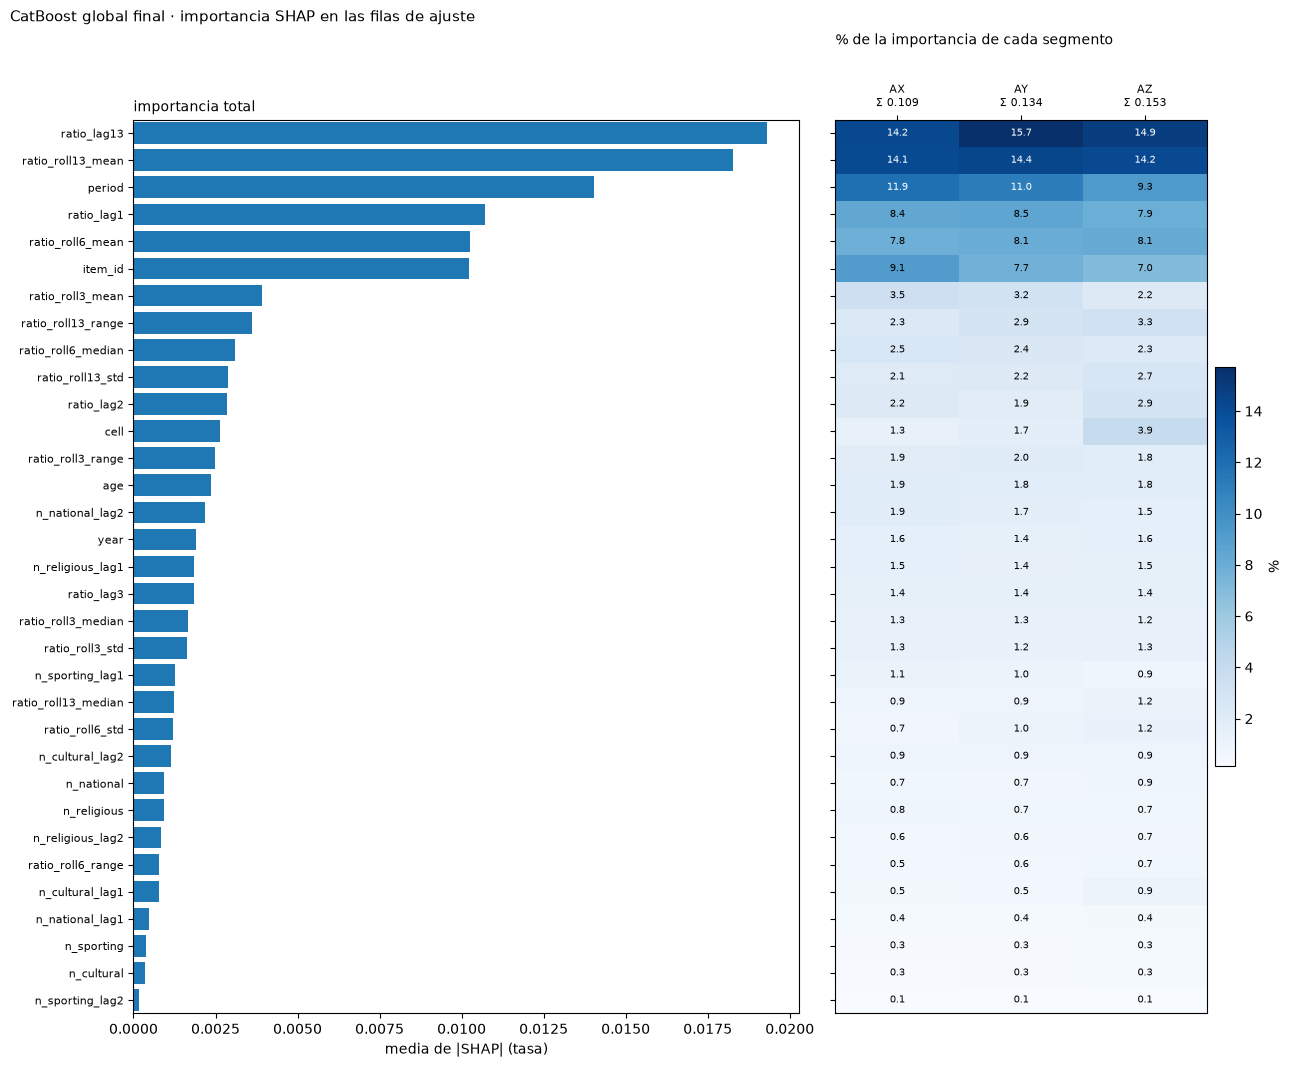

In [16]:
fig = plot_shap_importance(importance, "CatBoost global final · importancia SHAP en las filas de ajuste")
plt.show()


## Etapa 4 · Guardado del modelo y cierre

**Objetivo:** dejar en disco el CatBoost final de la Etapa 3 con todo lo que el nb 05 necesita para usarlo y para reentrenarlo igual en cada origen (D5).
**Entradas:** `model` y `fit_rows` (Etapa 3); `FEATURES`, `PARAMS`, `SEED`, `N_THREADS`, `manifest` y `catboost` (Etapa 1).
**Salidas:** `models/nb04_catboost/catboost_global.cbm` y `models/nb04_catboost/meta.json`.

**Decisión:**
- **Formato nativo `.cbm`**: lo lee CatBoost sin depender de pickle ni de la versión de Python.
- **`meta.json`**: algoritmo y objetivo (`ratio`), variables y categóricas, hiperparámetros, semilla e hilos, filas de ajuste (número, artículos, bloques y regla), origen (fecha del manifiesto del 03b; prueba, fecha y WRMSSE del 03c), versiones y fecha de guardado.
- **Candado:** si ya hay un modelo igual (mismo modelo según CatBoost y mismo meta, sin contar la fecha) no se escribe; si es distinto, se detiene salvo `OVERWRITE = True`. Se compara con la igualdad de CatBoost y no por bytes: dos guardados del mismo modelo no dan el mismo archivo.
- **Chequeos:** el modelo leído de disco es igual al de memoria y da las mismas predicciones en las filas de ajuste; el meta leído trae las mismas variables y los mismos hiperparámetros.


In [17]:
from src.modeling import load_catboost_model, save_catboost_model


In [18]:
fit_blocks = boosting_data.loc[fit_rows, "block"]
model_meta = {
    "algorithm": "catboost",
    "target": "ratio",
    "features": FEATURES,
    "cat_features": manifest["cat_features"],
    "params": PARAMS,
    "seed": SEED,
    "n_threads": N_THREADS,
    "fit": {"rule": "split == train y ratio no nulo", "rows": int(fit_rows.sum()),
            "items": int(boosting_data.loc[fit_rows, "item_id"].nunique()),
            "first_block": int(fit_blocks.min()), "last_block": int(fit_blocks.max())},
    "source": {"nb03b_saved_at": manifest["saved_at"], "nb03c_trial": catboost["meta"]["trial"],
               "nb03c_saved_at": catboost["meta"]["saved_at"], "nb03c_wrmsse": catboost["meta"]["wrmsse"]},
    "versions": {"python": platform.python_version(), **{lib: version(lib) for lib in LIBS}},
}
saved = save_catboost_model(model, model_meta, MODEL_DIR, overwrite=OVERWRITE)


In [19]:
loaded, loaded_meta = load_catboost_model(MODEL_DIR)
assert all(p.exists() for p in saved)
assert loaded == model
np.testing.assert_array_equal(loaded.predict(X_fit), model.predict(X_fit))
assert loaded_meta["features"] == FEATURES and loaded_meta["params"] == PARAMS
assert loaded_meta["fit"]["rows"] == int(fit_rows.sum())

display(pd.DataFrame({"archivo": [str(p) for p in saved], "KB": [round(p.stat().st_size / 1024, 1) for p in saved]}))
print(f"guardado: {loaded_meta['saved_at']} · {loaded_meta['fit']['rows']:,} filas, {loaded_meta['fit']['items']} artículos, "
      f"bloques {loaded_meta['fit']['first_block']}–{loaded_meta['fit']['last_block']}")


,archivo,KB
0,models/nb04_catboost/catboost_global.cbm,4752.8
1,models/nb04_catboost/meta.json,1.8


guardado: 2026-11-09T18:55:45 · 24,348 filas, 517 artículos, bloques 2–52


## Cierre

- **Modelo final:** un CatBoost global para los 517 artículos, entrenado con todo el train y los hiperparámetros congelados del 03c (prueba 43). Antes de entrenarlo se reprodujo exactamente el backtest del 03c (diferencia 0, WRMSSE 0,5062).
- **En la ventana de backtesting:** a un paso, WRMSSE en unidades 0,506 (WAPE 10,2 %); encadenado 13 bloques, como en producción, 0,742 (WAPE 20,2 %). En tasas casi no cambia (0,671 frente a 0,696): el error encadenado en unidades viene de acumular las tasas.
- **Qué usa el modelo:** sobre todo la tasa de hace 13 bloques, sus medias de 13 y 6 bloques, el periodo del año, la tasa anterior y el artículo; los eventos aportan poco. El orden es casi igual en AX, AY y AZ.
- **Para el nb 05:** `models/nb04_catboost/` (modelo y `meta.json`). El nb 05 mide el test con el pronóstico encadenado de 13 bloques y reentrena en cada origen con los mismos hiperparámetros, la misma semilla y los mismos hilos que dice el `meta.json`.
